# Indian Currency Classification — Balanced Seven-Denomination Evaluation

This notebook trains a MobileNetV3-Large classifier on all seven Indian denominations and evaluates it with **balanced test support**: the same number of test images per denomination.

## Supported denominations

`₹10, ₹20, ₹50, ₹100, ₹200, ₹500, ₹2000`

> This is an image-classification notebook for one mostly visible/cropped banknote per image. It is not a YOLO multi-note detector; that requires bounding-box annotations.


In [1]:
# Run once only if needed:
# %pip install torch torchvision scikit-learn pandas matplotlib seaborn pillow onnx onnxruntime

import os, json, random, hashlib, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score

warnings.filterwarnings("ignore")
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.14.0+cu126
Device: cuda
GPU: NVIDIA GeForce RTX 4070


## 1. Configuration

The expected dataset layout is:

```text
Indian Currency Dataset/
├── 10/
├── 20/
├── 50/
├── 100/
├── 200/
├── 500/
└── 2000/
```

`TEST_PER_CLASS` controls balanced test support. Every denomination must have at least `TEST_PER_CLASS + VAL_PER_CLASS + 1` unique images.


In [2]:
DATASET_ROOT = Path("Indian Currency Dataset")
OUTPUT_DIR = Path("currency_models_balanced")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["10", "20", "50", "100", "200", "500", "2000"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 35
PATIENCE = 8

# Exact, balanced evaluation support for each denomination.
TEST_PER_CLASS = 100
VAL_PER_CLASS = 100

if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_ROOT.resolve()}")
missing = [c for c in CLASS_NAMES if not (DATASET_ROOT / c).exists()]
if missing:
    raise FileNotFoundError(f"Missing class folders: {missing}")


## 2. Dataset audit and duplicate removal

Exact duplicate images are removed before splitting. This prevents the same file appearing in both training and test support. For best real-world validity, keep a separate external test set from a different phone, day, background, and capture session.


Readable images: 1786
Invalid images: 0
Exact duplicate records: 79

Unique images per denomination:
class_name
10      214
20      292
50      272
100     301
200     205
500     223
2000    239
Name: count, dtype: int64


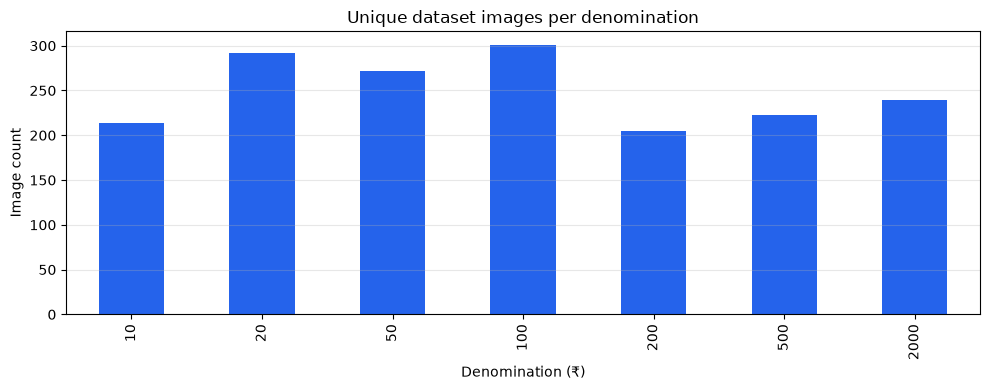

In [3]:
records, invalid_files = [], []
for class_name in CLASS_NAMES:
    for path in (DATASET_ROOT / class_name).rglob("*"):
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        try:
            with Image.open(path) as im:
                im.verify()
            with Image.open(path) as im:
                width, height = im.size
            records.append({
                "path": str(path), "class_name": class_name,
                "width": width, "height": height,
                "sha256": hashlib.sha256(path.read_bytes()).hexdigest()
            })
        except Exception as exc:
            invalid_files.append({"path": str(path), "error": str(exc)})

df = pd.DataFrame(records)
if df.empty: raise RuntimeError("No readable image files found.")

print("Readable images:", len(df))
print("Invalid images:", len(invalid_files))
print("Exact duplicate records:", int(df.sha256.duplicated(keep=False).sum()))
df = df.drop_duplicates(subset="sha256", keep="first").reset_index(drop=True)

counts = df.class_name.value_counts().reindex(CLASS_NAMES)
print("\nUnique images per denomination:")
print(counts)

minimum_required = TEST_PER_CLASS + VAL_PER_CLASS + 1
insufficient = counts[counts < minimum_required]
if len(insufficient):
    raise ValueError(
        f"Insufficient unique images for balanced evaluation. Each class needs at least "
        f"{minimum_required}; insufficient classes: {insufficient.to_dict()}"
    )

plt.figure(figsize=(10, 4))
counts.plot(kind="bar", color="#2563eb")
plt.title("Unique dataset images per denomination")
plt.xlabel("Denomination (₹)"); plt.ylabel("Image count"); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()


## 3. Balanced split construction

For every denomination, the notebook reserves exactly:

- `TEST_PER_CLASS` images for the held-out test set;
- `VAL_PER_CLASS` images for validation;
- all remaining images for training.

Therefore each denomination has equal influence in the test results. Training uses all remaining images, so it can still be proportionate to available data.


In [4]:
rng = np.random.default_rng(SEED)
train_rows, val_rows, test_rows = [], [], []

for class_name in CLASS_NAMES:
    class_frame = df[df.class_name == class_name].sample(frac=1, random_state=SEED).reset_index(drop=True)
    test_rows.append(class_frame.iloc[:TEST_PER_CLASS])
    val_rows.append(class_frame.iloc[TEST_PER_CLASS:TEST_PER_CLASS + VAL_PER_CLASS])
    train_rows.append(class_frame.iloc[TEST_PER_CLASS + VAL_PER_CLASS:])

train_df = pd.concat(train_rows, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df = pd.concat(val_rows, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
test_df = pd.concat(test_rows, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)

for name, split_df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"\n{name.upper()} images: {len(split_df)}")
    print(split_df.class_name.value_counts().reindex(CLASS_NAMES).to_dict())

assert all(test_df.class_name.value_counts().reindex(CLASS_NAMES) == TEST_PER_CLASS)
assert all(val_df.class_name.value_counts().reindex(CLASS_NAMES) == VAL_PER_CLASS)

train_df.assign(split="train").to_csv(OUTPUT_DIR / "train_manifest.csv", index=False)
val_df.assign(split="val").to_csv(OUTPUT_DIR / "val_manifest.csv", index=False)
test_df.assign(split="test").to_csv(OUTPUT_DIR / "balanced_test_manifest.csv", index=False)
print("\n✅ Balanced test support confirmed:", TEST_PER_CLASS, "images ×", len(CLASS_NAMES), "denominations =", len(test_df), "test images")



TRAIN images: 346
{'10': 14, '20': 92, '50': 72, '100': 101, '200': 5, '500': 23, '2000': 39}

VALIDATION images: 700
{'10': 100, '20': 100, '50': 100, '100': 100, '200': 100, '500': 100, '2000': 100}

TEST images: 700
{'10': 100, '20': 100, '50': 100, '100': 100, '200': 100, '500': 100, '2000': 100}

✅ Balanced test support confirmed: 100 images × 7 denominations = 700 test images


## 4. Transforms and DataLoaders

Augmentation is applied only to training data. Horizontal flips are intentionally disabled because banknotes contain directional text, portraits, and security features.


In [5]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.65, 1.0), ratio=(0.70, 1.35)),
    transforms.RandomPerspective(distortion_scale=0.20, p=0.35),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.85, 1.10), shear=5),
    transforms.ColorJitter(brightness=.30, contrast=.30, saturation=.25, hue=.03),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(.1, 1.8))], p=.20),
    transforms.ToTensor(),
    transforms.RandomErasing(p=.15, scale=(.01,.08), ratio=(.3,3.3), value="random"),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CurrencyDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as image:
            image = image.convert("RGB")
        return self.transform(image), CLASS_TO_IDX[row.class_name], row.path

train_dataset = CurrencyDataset(train_df, train_transform)
val_dataset = CurrencyDataset(val_df, eval_transform)
test_dataset = CurrencyDataset(test_df, eval_transform)

# Proportionate training while avoiding majority-class dominance in batches.
train_counts = Counter(train_df.class_name)
weights = [1.0 / train_counts[c] for c in train_df.class_name]
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

workers = 2 if os.name != "nt" else 0
pin_memory = torch.cuda.is_available()
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=workers, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE*2, shuffle=False, num_workers=workers, pin_memory=pin_memory)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE*2, shuffle=False, num_workers=workers, pin_memory=pin_memory)


## 5. Model: MobileNetV3-Large

MobileNetV3-Large starts with ImageNet pretrained features, then replaces its final classifier with a seven-class head. The best checkpoint is selected using validation macro-F1, which weights each denomination equally.


In [6]:
def build_model(num_classes=7):
    model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
    features = model.classifier[0].in_features
    model.classifier = nn.Sequential(
        nn.Linear(features, 512), nn.BatchNorm1d(512), nn.Hardswish(), nn.Dropout(.35),
        nn.Linear(512, 128), nn.BatchNorm1d(128), nn.Hardswish(), nn.Dropout(.20),
        nn.Linear(128, num_classes)
    )
    return model

model = build_model(len(CLASS_NAMES)).to(DEVICE)
criterion = nn.CrossEntropyLoss(label_smoothing=.10)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Trainable parameters: 3531831


In [7]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []
    for images, labels, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(images)
            loss = criterion(logits, labels)
        if training:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(optimizer); scaler.update()
        total_loss += loss.item() * labels.size(0)
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().numpy())
    return total_loss / len(loader.dataset), np.array(y_true), np.array(y_pred)

best_f1, stale = -1.0, 0
checkpoint_path = OUTPUT_DIR / "best_currency_model.pth"
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, train_true, train_pred = run_epoch(train_loader, training=True)
    val_loss, val_true, val_pred = run_epoch(val_loader, training=False)
    val_macro_f1 = f1_score(val_true, val_pred, average="macro", zero_division=0)
    val_balanced_acc = balanced_accuracy_score(val_true, val_pred)
    scheduler.step()
    history.append({
        "epoch":epoch, "train_loss":train_loss, "val_loss":val_loss,
        "val_macro_f1":val_macro_f1, "val_balanced_accuracy":val_balanced_acc
    })
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val macro-F1 {val_macro_f1:.4f} | val balanced accuracy {val_balanced_acc:.4f}")
    if val_macro_f1 > best_f1:
        best_f1, stale = val_macro_f1, 0
        torch.save({
            "model_state_dict":model.state_dict(), "class_names":CLASS_NAMES,
            "mean":MEAN, "std":STD, "img_size":IMG_SIZE,
            "epoch":epoch, "val_macro_f1":float(val_macro_f1)
        }, checkpoint_path)
    else:
        stale += 1
        if stale >= PATIENCE:
            print("Early stopping.")
            break

pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)


Epoch 01/35 | train loss 1.6322 | val loss 1.8511 | val macro-F1 0.2643 | val balanced accuracy 0.3229
Epoch 02/35 | train loss 1.1382 | val loss 1.5762 | val macro-F1 0.4793 | val balanced accuracy 0.5186
Epoch 03/35 | train loss 0.8822 | val loss 1.2467 | val macro-F1 0.7222 | val balanced accuracy 0.7486
Epoch 04/35 | train loss 0.7375 | val loss 1.0380 | val macro-F1 0.7715 | val balanced accuracy 0.7900
Epoch 05/35 | train loss 0.6000 | val loss 0.9591 | val macro-F1 0.7887 | val balanced accuracy 0.8014
Epoch 06/35 | train loss 0.5823 | val loss 0.9479 | val macro-F1 0.7826 | val balanced accuracy 0.7986
Epoch 07/35 | train loss 0.5374 | val loss 0.8973 | val macro-F1 0.8055 | val balanced accuracy 0.8229
Epoch 08/35 | train loss 0.5228 | val loss 0.8533 | val macro-F1 0.8262 | val balanced accuracy 0.8414
Epoch 09/35 | train loss 0.5252 | val loss 0.8275 | val macro-F1 0.8369 | val balanced accuracy 0.8486
Epoch 10/35 | train loss 0.5135 | val loss 0.7976 | val macro-F1 0.8575 |

## 6. Balanced held-out test evaluation

Because every denomination has exactly the same test support, overall accuracy, balanced accuracy, and macro-F1 are directly meaningful. Report the per-class results rather than only a single accuracy number.


BALANCED SEVEN-DENOMINATION HELD-OUT TEST RESULTS
Test support per denomination: 100
Total balanced test images: 700
Accuracy:          0.9243
Balanced accuracy: 0.9243
Macro-F1:          0.9197

Per-class report:

              precision    recall  f1-score   support

         ₹10     0.9694    0.9500    0.9596       100
         ₹20     0.7299    1.0000    0.8439       100
         ₹50     0.9604    0.9700    0.9652       100
        ₹100     0.9612    0.9900    0.9754       100
        ₹200     0.9655    0.5600    0.7089       100
        ₹500     1.0000    1.0000    1.0000       100
       ₹2000     0.9709    1.0000    0.9852       100

    accuracy                         0.9243       700
   macro avg     0.9368    0.9243    0.9197       700
weighted avg     0.9368    0.9243    0.9197       700



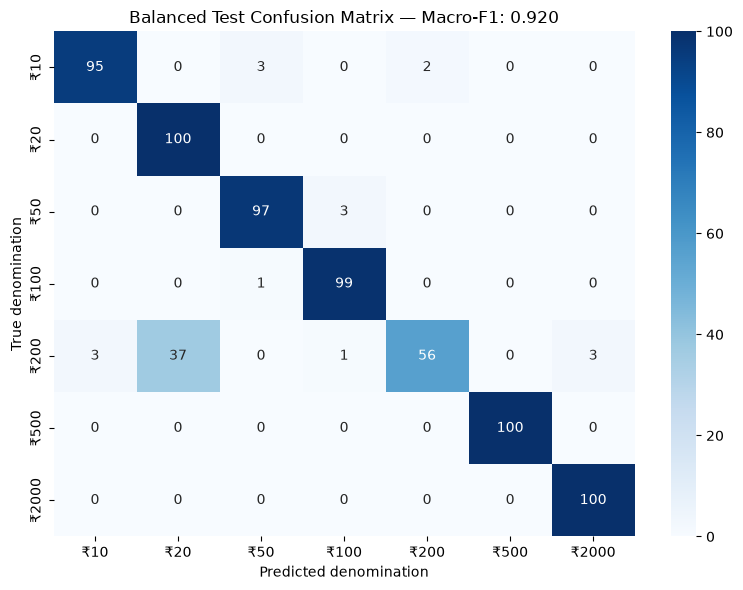

✅ Verified: each of the 7 classes has exactly 100 test images.


In [8]:
checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_loss, y_true, y_pred = run_epoch(test_loader, training=False)
accuracy = accuracy_score(y_true, y_pred)
balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("="*70)
print("BALANCED SEVEN-DENOMINATION HELD-OUT TEST RESULTS")
print("="*70)
print("Test support per denomination:", TEST_PER_CLASS)
print("Total balanced test images:", len(test_df))
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")
print(f"Macro-F1:          {macro_f1:.4f}")
print("\nPer-class report:\n")
print(classification_report(y_true, y_pred, target_names=[f"₹{x}" for x in CLASS_NAMES], digits=4, zero_division=0))

report = classification_report(y_true, y_pred, target_names=[f"₹{x}" for x in CLASS_NAMES], output_dict=True, zero_division=0)
pd.DataFrame(report).T.to_csv(OUTPUT_DIR / "balanced_test_classification_report.csv")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=[f"₹{x}" for x in CLASS_NAMES], yticklabels=[f"₹{x}" for x in CLASS_NAMES])
plt.title(f"Balanced Test Confusion Matrix — Macro-F1: {macro_f1:.3f}")
plt.xlabel("Predicted denomination"); plt.ylabel("True denomination")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "balanced_test_confusion_matrix.png", dpi=180); plt.show()

per_class_support = pd.Series(y_true).value_counts().sort_index()
assert all(per_class_support.values == TEST_PER_CLASS), "Test support is not balanced."
print("✅ Verified: each of the 7 classes has exactly", TEST_PER_CLASS, "test images.")


## 7. Visualize training history


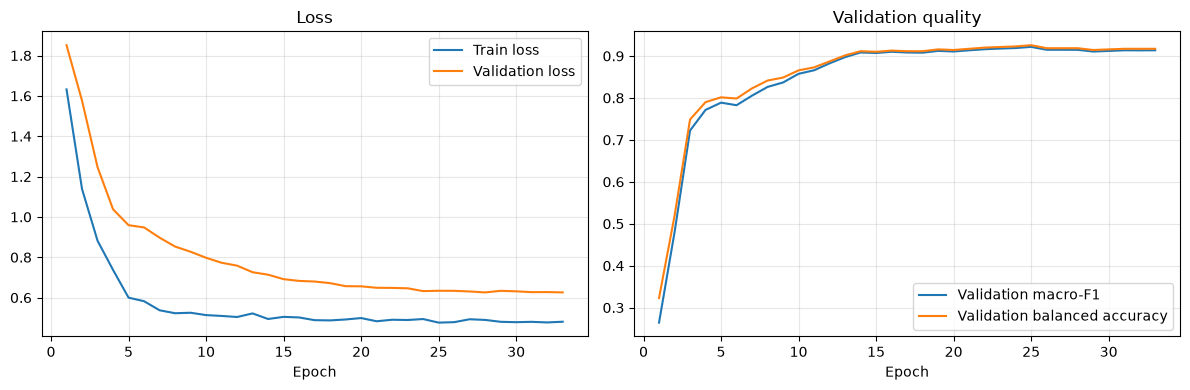

In [9]:
history_df = pd.read_csv(OUTPUT_DIR / "training_history.csv")
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(history_df.epoch, history_df.train_loss, label="Train loss")
axes[0].plot(history_df.epoch, history_df.val_loss, label="Validation loss")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(history_df.epoch, history_df.val_macro_f1, label="Validation macro-F1")
axes[1].plot(history_df.epoch, history_df.val_balanced_accuracy, label="Validation balanced accuracy")
axes[1].set_title("Validation quality"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


## 8. Confidence-aware inference

A classification model always chooses a class. In deployment, reject low-confidence predictions instead of announcing an unreliable denomination.


In [10]:
def predict_currency(image_input, confidence_threshold=0.75):
    if isinstance(image_input, (str, Path)):
        image = Image.open(image_input).convert("RGB")
    elif isinstance(image_input, np.ndarray):
        image = Image.fromarray(image_input).convert("RGB")
    else:
        image = image_input.convert("RGB")
    x = eval_transform(image).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        probabilities = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    pred_idx = int(probabilities.argmax())
    confidence = float(probabilities[pred_idx])
    denomination = CLASS_NAMES[pred_idx]
    accepted = confidence >= confidence_threshold
    message = (f"{denomination} rupee note detected with {confidence*100:.1f} percent confidence."
               if accepted else
               "Unable to verify the note. Hold one banknote flat and closer to the camera in better lighting.")
    return {
        "accepted": accepted, "denomination": denomination, "confidence": confidence,
        "probabilities": {f"₹{c}": float(probabilities[i]) for i,c in enumerate(CLASS_NAMES)},
        "message": message
    }

# Example:
# print(predict_currency("your_test_note.jpg"))


## 9. ONNX export

Export the trained classifier for Hugging Face or edge deployment. The `labels.json` file preserves the exact denomination order and preprocessing values.


In [11]:
import onnx
onnx_path = OUTPUT_DIR / "currency_model.onnx"
model.eval()
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=["input_image"], output_names=["class_logits"],
    dynamic_axes={"input_image":{0:"batch"}, "class_logits":{0:"batch"}},
    opset_version=17
)
onnx.checker.check_model(str(onnx_path))

labels = {
    "class_names": CLASS_NAMES, "class_to_idx": CLASS_TO_IDX,
    "mean": MEAN, "std": STD, "img_size": IMG_SIZE,
    "confidence_threshold": 0.75,
    "balanced_test_per_class": TEST_PER_CLASS
}
with open(OUTPUT_DIR / "labels.json", "w", encoding="utf-8") as f:
    json.dump(labels, f, indent=2)

print("Saved model:", onnx_path)
print("Model size MB:", round(onnx_path.stat().st_size/(1024**2), 2))
print("Saved metadata:", OUTPUT_DIR / "labels.json")


W1015 12:14:20.285000 15376 torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W1015 12:14:21.239000 15376 torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 17 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "C:\Users\lab\AppData\Roaming\Python\Python314\site-packages\onnxscript\version_converter\__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "C:\Users\lab\AppData\Roaming\Python\Python314\site-packages\onnxscript\version_converter\_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "C:\Users\lab\AppData\Roaming\Python\Python314\site-packages\onnxscript\version_converter\__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\lab\AppData\Roaming\Python\Python314\site-packages\onnx\version_converter.py", li

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Saved model: currency_models_balanced\currency_model.onnx
Model size MB: 0.34
Saved metadata: currency_models_balanced\labels.json


## Reporting statement

Use this in your report or PPT after the notebook has run:

> The model was trained across all seven Indian currency denominations—₹10, ₹20, ₹50, ₹100, ₹200, ₹500, and ₹2000. Evaluation used a balanced held-out test set with the same number of images per denomination. Performance was reported through accuracy, balanced accuracy, macro-F1, per-class precision and recall, and a confusion matrix.

Do not call this real-world generalization unless you also evaluate on a separately captured external test set.
